In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
base = 'aaus7_class_'
file_format = '.csv'
tel = pd.read_csv(base+'timestamped_telemetry'+file_format,parse_dates=['observed_at'])
#tel.info()
ops = pd.read_csv(base+'operations_log'+file_format,parse_dates=['logged_at'])
#ops.info()
bal = pd.read_csv(base+'daily_water_balance'+file_format,parse_dates=['report_date']) 
#bal.info()
inc = pd.read_csv(base+'service_incidents'+file_format,parse_dates=['event_time','closed_at'])
#inc.info()
asset = pd.read_csv(base+'asset_reference'+file_format,parse_dates=['installation_year'])
#asset.info()
kpi = pd.read_csv(base+'monthly_kpis_wide'+file_format,parse_dates=['month'])
kpi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   month                      36 non-null     datetime64[ns]
 1   zone                       36 non-null     object        
 2   supply_reliability_pct     36 non-null     float64       
 3   billing_collection_pct     36 non-null     float64       
 4   quality_compliance_pct     36 non-null     float64       
 5   customer_satisfaction_pct  36 non-null     float64       
 6   report_status              36 non-null     object        
dtypes: datetime64[ns](1), float64(4), object(2)
memory usage: 2.1+ KB


In [24]:
left = pd.DataFrame({
'day':[1,3],
'supplied':[40,52]})
right = pd.DataFrame({
'day':[2,3],
'target':[45,50]})
ordered = pd.merge_ordered(
left, right, on='day')
print(ordered.to_string(index=False))

 day  supplied  target
   1      40.0     NaN
   2       NaN    45.0
   3      52.0    50.0


In [25]:
filled = pd.merge_ordered(
left, right,
on='day',
fill_method='ffill'
)
print(filled.to_string(index=False))

 day  supplied  target
   1        40     NaN
   2        40    45.0
   3        52    50.0


In [5]:
tl = tel.sort_values('observed_at')
op = ops.sort_values('logged_at')
print('sensor sorted:', 
tl.observed_at.is_monotonic_increasing)
print('log sorted:', 
op.logged_at.is_monotonic_increasing)
print('zones:', tl.zone.nunique())
tl
op

sensor sorted: True
log sorted: True
zones: 6


,log_id,logged_at,zone,pump_mode,active_units,power_event,staff_shift,supervisor_team
8,OP-00009,2026-01-05 05:01:00,Gullele,Conservation,3,No,Early,Ops-C
4,OP-00005,2026-01-05 05:06:00,Lideta,Normal,5,No,Early,Ops-A
0,OP-00001,2026-01-05 05:11:00,Akaki,Conservation,3,No,Early,Ops-B
6,OP-00007,2026-01-05 05:17:00,Merkato,Normal,2,No,Early,Ops-B
2,OP-00003,2026-01-05 05:22:00,Kirkos,Booster,4,No,Early,Ops-C
...,...,...,...,...,...,...,...,...
986,OP-00987,2026-04-04 17:08:00,Bole,Booster,3,No,Late,Ops-A
996,OP-00997,2026-04-04 17:09:00,Gullele,Normal,4,No,Late,Ops-C
992,OP-00993,2026-04-04 17:14:00,Lideta,Conservation,2,No,Late,Ops-A
988,OP-00989,2026-04-04 17:19:00,Akaki,Normal,4,No,Late,Ops-B


In [6]:
aligned = pd.merge_asof(
tl, op,
left_on='observed_at',
right_on='logged_at', by='zone',
direction='backward',
tolerance=pd.Timedelta('18h'))
print('left rows:', len(tl), 'joined:', 
len(aligned))
print('matched:', 
int(aligned.log_id.notna().sum()))
aligned

left rows: 1045 joined: 1045
matched: 1016


,reading_id,observed_at,zone,station_id,sensor_vendor,shift,pressure_bar,flow_lps,chlorine_mg_l,battery_pct,quality_flag,log_id,logged_at,pump_mode,active_units,power_event,staff_shift,supervisor_team
0,TR-00008,2026-01-05 08:05:00,Merkato,ST-ME-01,HydroSense,Day,2.08,81.8,0.410,100,Valid,OP-00007,2026-01-05 05:17:00,Normal,2.0,No,Early,Ops-B
1,TR-00002,2026-01-05 08:07:00,Akaki,ST-AK-01,HydroSense,Day,1.69,66.2,0.290,79,Valid,OP-00001,2026-01-05 05:11:00,Conservation,3.0,No,Early,Ops-B
2,TR-00010,2026-01-05 08:12:00,Gullele,ST-GU-01,Civic Metering,Day,2.21,87.0,0.450,78,Valid,OP-00009,2026-01-05 05:01:00,Conservation,3.0,No,Early,Ops-C
3,TR-00004,2026-01-05 08:14:00,Kirkos,ST-KI-01,Civic Metering,Day,1.82,71.4,0.330,86,Valid,OP-00003,2026-01-05 05:22:00,Booster,4.0,No,Early,Ops-C
4,TR-00006,2026-01-05 08:21:00,Lideta,ST-LI-01,Acme Instruments,Day,1.95,76.6,0.370,93,Valid,OP-00005,2026-01-05 05:06:00,Normal,5.0,No,Early,Ops-A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1040,TR-01035,2026-04-04 20:04:00,Bole,ST-BS-03,Acme Instruments,Night,2.12,84.4,0.268,83,Valid,OP-00987,2026-04-04 17:08:00,Booster,3.0,No,Late,Ops-A
1041,TR-01043,2026-04-04 20:09:00,Merkato,ST-ME-03,HydroSense,Night,2.64,105.2,0.428,82,Valid,OP-00995,2026-04-04 17:25:00,Booster,3.0,No,Late,Ops-B
1042,TR-01037,2026-04-04 20:11:00,Akaki,ST-AK-03,HydroSense,Night,2.25,89.6,0.308,90,Valid,OP-00989,2026-04-04 17:19:00,Normal,4.0,No,Late,Ops-B
1043,TR-01045,2026-04-04 20:16:00,Gullele,ST-GU-03,Civic Metering,Night,2.77,110.4,0.468,89,Valid,OP-00997,2026-04-04 17:09:00,Normal,4.0,No,Late,Ops-C


In [7]:
aligned['matched_log'] = aligned.log_id.notna()
matched = int(aligned.matched_log.sum())
missing = int((~aligned.matched_log).sum())
print('matched:',matched,'unmatched:',missing)
print('coverage %:',round(100*matched/len(aligned),1))

matched: 1016 unmatched: 29
coverage %: 97.2


In [9]:
aligned['matched_log'] = aligned.log_id.notna()
matched = int(aligned.matched_log.sum())
missing = int((~aligned.matched_log).sum())
print('matched:',matched,'unmatched:',missing)
print('coverage %:',round(100*matched/len(aligned),1))

matched: 1016 unmatched: 29
coverage %: 97.2


In [10]:
unbounded = pd.merge_asof(
tl, op,
left_on='observed_at',
right_on='logged_at', by='zone',
direction='backward')
print('no limit matches:',
int(unbounded.log_id.notna().sum()))
print('18h matches:',
int(aligned.log_id.notna().sum()))

no limit matches: 1044
18h matches: 1016


In [13]:
forward = pd.merge_asof(
tl, op,
left_on='observed_at',
right_on='logged_at', by='zone',
direction='forward',
tolerance=pd.Timedelta('18h'))
print('forward matched:',int(forward.log_id.notna().sum()))

forward matched: 961


In [16]:
zone_coverage = aligned.groupby('zone').agg(
    observations=('reading_id','size'),
    matched=('matched_log','sum'))
zone_coverage['pct'] = (100*zone_coverage.matched/zone_coverage.observations).round(1)
print(zone_coverage[['pct']].T.round(1).to_string())

zone  Akaki  Bole  Gullele  Kirkos  Lideta  Merkato
pct    96.6  97.7     97.7    96.6    96.6     98.3


<Axes: xlabel='zone', ylabel='Matched %'>

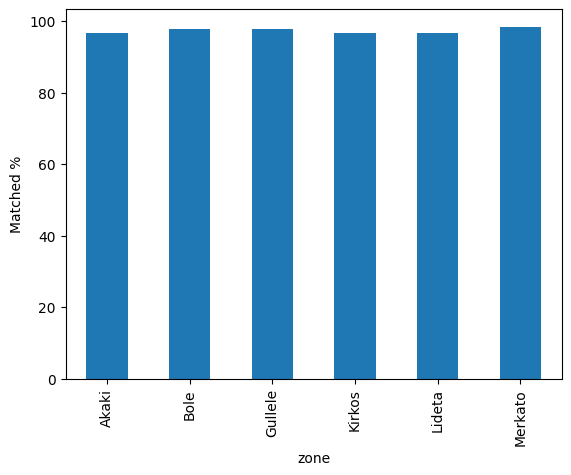

In [18]:
zone_coverage['pct'].plot(kind='bar',ylabel='Matched %')


In [19]:
zone_daily = bal.query("zone == 'Bole'")
zone_daily = zone_daily.set_index('report_date')
monthly_supply = (
zone_daily.water_produced_m3.resample('MS').sum()
)
print(monthly_supply.round(0).to_dict())

{Timestamp('2026-01-01 00:00:00'): 338040, Timestamp('2026-02-01 00:00:00'): 357640, Timestamp('2026-03-01 00:00:00'): 404980, Timestamp('2026-04-01 00:00:00'): 54940}


In [23]:
daily_zone = zone_daily.sort_index()
daily_zone['prod_avg7'] = (
    daily_zone.water_produced_m3.rolling(
7, min_periods=3).mean())
print('non-null rolling values:',
int(daily_zone.prod_avg7.notna().sum()))

non-null rolling values: 88


In [24]:
monthly_ops = zone_daily.resample('MS').agg({
'water_produced_m3': 'sum',
'water_billed_m3': 'sum',
'outage_minutes': 'sum'
})
print(monthly_ops.head(3).round(0).to_string())

             water_produced_m3  water_billed_m3  outage_minutes
report_date                                                    
2026-01-01              338040         242682.0            1170
2026-02-01              357640         252340.0            1260
2026-03-01              404980         290492.0            1365


In [25]:
daily_zone['cumulative_m3'] = (daily_zone.water_produced_m3.cumsum())
print('final cumulative m3:',
round(daily_zone.cumulative_m3.iloc[-1],0))
print('last 7-day mean m3:',
round(daily_zone.prod_avg7.iloc[-1],1))

final cumulative m3: 1155600
last 7-day mean m3: 13390.0


In [26]:
daily_zone['cumulative_m3'] = (
    daily_zone.water_produced_m3.cumsum())
print('final cumulative m3:',
round(daily_zone.cumulative_m3.iloc[-1],0))
print('last 7-day mean m3:',
round(daily_zone.prod_avg7.iloc[-1],1))

final cumulative m3: 1155600
last 7-day mean m3: 13390.0


In [27]:
monthly_ops['production_change_pct'] = (
100*monthly_ops.water_produced_m3.pct_change())
print('first change is NaN:',
      pd.isna(monthly_ops.production_change_pct.iloc[0]))
print('last change %:',
round(monthly_ops.production_change_pct.iloc[-1],1))

first change is NaN: True
last change %: -86.4


In [29]:
monthly_ops['production_change_pct'] = (
100*monthly_ops.water_produced_m3.pct_change())
print('first change is NaN:',
      pd.isna(monthly_ops.production_change_pct.iloc[0]))
print('last change %:',
round(monthly_ops.production_change_pct.iloc[-1],1))

first change is NaN: True
last change %: -86.4


<Axes: xlabel='report_date', ylabel='m³ per month'>

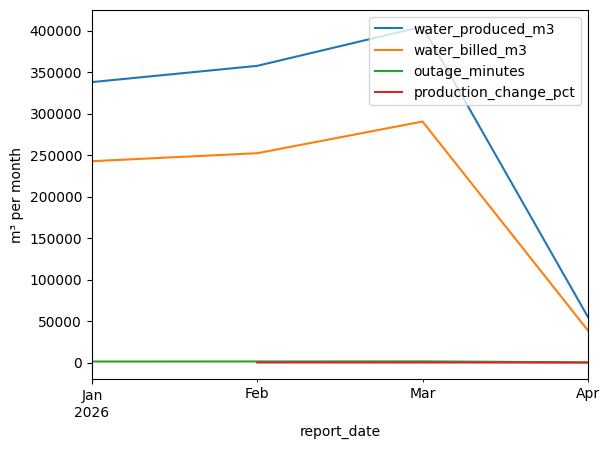

In [31]:
monthly_ops.plot(kind='line',ylabel='m³ per month')

In [32]:
print('rows:', len(kpi))
print('metric columns:',
[c for c in kpi if 
c.endswith('_pct')])
print('zones:', kpi.zone.nunique())

rows: 36
metric columns: ['supply_reliability_pct', 'billing_collection_pct', 'quality_compliance_pct', 'customer_satisfaction_pct']
zones: 6


In [33]:
metric_cols = [c for c in kpi if 
c.endswith('_pct')]
long = kpi.melt(
id_vars=['month','zone','report_status'],
value_vars=metric_cols,
var_name='metric',value_name='value_pct')
print('wide rows:', len(kpi), 'long rows:', 
len(long))
print('metrics:', long.metric.nunique())

wide rows: 36 long rows: 144
metrics: 4


In [34]:
reliability = long.query(
"metric == 'supply_reliability_pct'"
)
print('reliability rows:', len(reliability))
print('zones:', reliability.zone.nunique())
print('months:', reliability.month.nunique())

reliability rows: 36
zones: 6
months: 6


In [35]:
expected = len(kpi)*len(metric_cols)
print('expected long rows:', expected)
print('actual long rows:', len(long))
print('values missing:', 
int(long.value_pct.isna().sum()))

expected long rows: 144
actual long rows: 144
values missing: 0


In [37]:
metric_cols = [c for c in kpi if 
c.endswith('_pct')]
long = kpi.melt(
id_vars=['month','zone','report_status'],
value_vars=metric_cols,
var_name='metric',value_name='value_pct')
print('wide rows:', len(kpi), 'long rows:', 
len(long))
print('metrics:', long.metric.nunique())
metric_cols

wide rows: 36 long rows: 144
metrics: 4


['supply_reliability_pct',
 'billing_collection_pct',
 'quality_compliance_pct',
 'customer_satisfaction_pct']

In [38]:
reliability = long.query(
"metric == 'supply_reliability_pct'"
)
print('reliability rows:', len(reliability))
print('zones:', reliability.zone.nunique())
print('months:', reliability.month.nunique())

reliability rows: 36
zones: 6
months: 6


In [40]:
expected = len(kpi)*len(metric_cols)
print('expected long rows:', expected)
print('actual long rows:', len(long))
print('values missing:', 
int(long.value_pct.isna().sum()))
expected

expected long rows: 144
actual long rows: 144
values missing: 0


144

In [43]:
bal['nrw_pct'] = 100*np.where(
bal.water_produced_m3 > 0,
(bal.water_produced_m3-bal.water_billed_m3)
/bal.water_produced_m3, np.nan)
print('negative NRW rows:', 
int((bal.nrw_pct<0).sum()))
print('median NRW %:', 
round(bal.nrw_pct.median(), 1))

negative NRW rows: 7
median NRW %: 26.8


In [44]:
bal['quality_issue'] = np.select(
[bal.water_billed_m3 > bal.water_produced_m3,
bal.water_produced_m3 <= 0],
['Billing above production',
'Invalid production'],
default='OK')
print(bal.quality_issue.value_counts().to_dict())

{'OK': 533, 'Billing above production': 7}


In [47]:
valid_bal = bal.query("quality_issue == 'OK'").copy()
valid_bal['month'] = valid_bal.report_date.dt.to_period('M')
summary = valid_bal.groupby(['zone','month']).agg(
produced=('water_produced_m3','sum'),
billed=('water_billed_m3','sum'))
print('monthly zone rows:',len(summary))

monthly zone rows: 24


In [48]:
summary['nrw_pct'] = (
100*(summary.produced-summary.billed)
/summary.produced)
print('monthly KPI min/max %:',
round(summary.nrw_pct.min(),1),
round(summary.nrw_pct.max(),1))

monthly KPI min/max %: 24.3 29.6


In [49]:
pivot = summary.reset_index().pivot(
index='month',columns='zone',values='nrw_pct')
print('shape:',pivot.shape)
print('months:',len(pivot),'zones:',len(pivot.columns))

shape: (4, 6)
months: 4 zones: 6


In [50]:
assets = pd.read_csv(base+'asset_reference.csv')
print('asset IDs unique:',assets.asset_id.is_unique)
print('incidents:',len(inc))
print('zones with incidents:',inc.zone.nunique())

asset IDs unique: True
incidents: 270
zones with incidents: 6


In [51]:
q1 = pd.read_csv(base+'asset_inspections_Q1.csv')
q2 = pd.read_csv(base+'asset_inspections_Q2.csv')
inspection = pd.concat([q1,q2],ignore_index=True)
print('Q1 fields:',len(q1.columns),'Q2:',len(q2.columns))
print('combined rows:',len(inspection))

Q1 fields: 6 Q2: 7
combined rows: 240


In [52]:
print('followup missing:',
int(inspection.followup_required.isna().sum()))
print('unique IDs:',inspection.inspection_id.is_unique)
print('result counts:',
inspection.result.value_counts().to_dict())

followup missing: 120
unique IDs: True
result counts: {'Pass': 120, 'Attention': 60, 'Fail': 60}


<Axes: xlabel='category', ylabel='Incidents'>

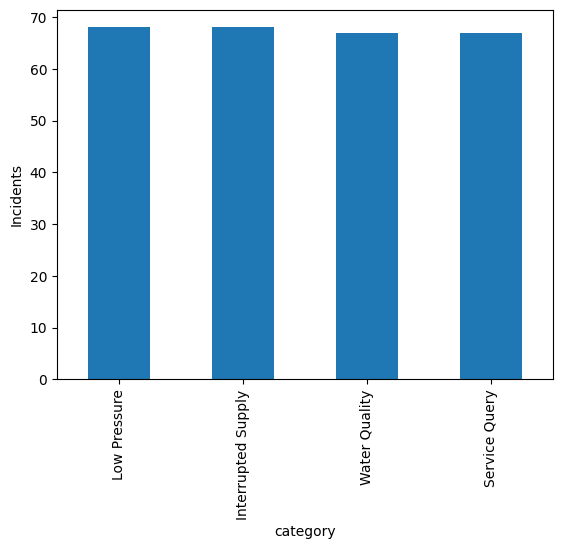

In [53]:
inc.category.value_counts().plot(kind='bar', 
ylabel='Incidents')

<Axes: ylabel='Frequency'>

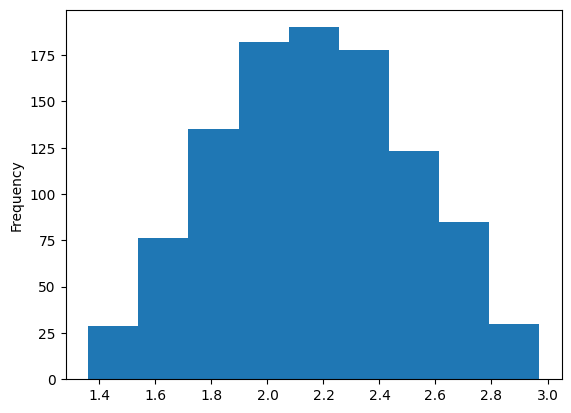

In [54]:
tel.pressure_bar.plot(kind='hist', bins=9)

<Axes: xlabel='pressure_bar', ylabel='flow_lps'>

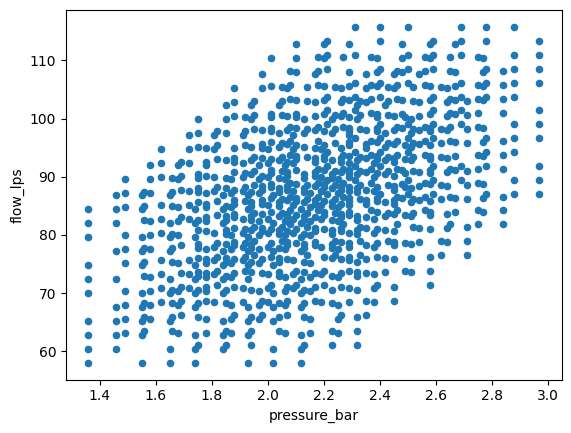

In [55]:
tel.plot.scatter(x='pressure_bar', y='flow_lps')

In [56]:
tel.groupby('zone').pressure_bar.quantile([.25,.5,.75])

zone         
Akaki    0.25    1.78
         0.50    1.97
         0.75    2.17
Bole     0.25    1.65
         0.50    1.85
         0.75    2.04
Gullele  0.25    2.29
         0.50    2.50
         0.75    2.69
Kirkos   0.25    1.91
         0.50    2.09
         0.75    2.29
Lideta   0.25    2.04
         0.50    2.23
         0.75    2.43
Merkato  0.25    2.17
         0.50    2.37
         0.75    2.56
Name: pressure_bar, dtype: float64

In [58]:
report = summary.reset_index().copy()
report['month'] = report.month.astype(str)
cols = ['zone','month','produced','billed','nrw_pct']
report[cols].to_csv('session7_zone_kpis.csv',
index=False)
print('exported rows:', len(report))
print('output columns:', len(cols))

exported rows: 24
output columns: 5


In [59]:
check = pd.read_csv('session7_zone_kpis.csv')
assert len(check) == len(report)
assert check[['zone','month']].duplicated().sum() == 0
assert check.produced.ge(check.billed).all()
print('rows verified:', len(check))
print('duplicate zone-month keys: 0')

rows verified: 24
duplicate zone-month keys: 0
